# Thí nghiệm XGBoost: dự báo biến động và cảnh báo HIGH

Notebook này tái hiện cấu hình XGBoost hiện tại trong config.yaml và src/models/xgboost_tuning.py. Mô hình hồi quy dự báo độ lệch chuẩn mẫu của lợi suất log trong 5 phiên kế tiếp, theo điểm phần trăm. Siêu tham số được chọn bằng 5 fold theo thời gian: tối đa hóa average precision (AP) cho lớp HIGH trong nhóm cấu hình có RMSE không vượt quá 5% so với RMSE tốt nhất. Ngưỡng cảnh báo được hiệu chỉnh riêng trên validation theo chính sách XGBoost: tối đa 30% cảnh báo, precision tối thiểu 25%. Tập test chỉ dùng để báo cáo kết quả cuối.

Chạy notebook từ thư mục gốc repository hoặc từ thư mục notebooks. Dữ liệu được đọc từ tệp cục bộ; notebook không tải dữ liệu từ mạng.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import ParameterGrid

ROOT = Path.cwd()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.config import load_config
from src.pipeline.dataset import prepare_dataset, valid_history
from src.models.xgboost_tuning import tune_xgboost
from src.models.xgboost_model import XGBoostModel
from src.risk.warning_engine import WarningEngine
from src.evaluation.regression import regression_metrics
from src.evaluation.warning_metrics import (
    calibrate_high_threshold, high_warning_metrics, risk_level_metrics,
)

config = load_config(ROOT / "config.yaml")
ticker = config["data"].get("ticker", "ACB")
dataset = prepare_dataset(ticker, config)
history = valid_history(dataset)
warning = WarningEngine(**config["warning"]).fit(dataset.train[dataset.target])

print(f"Mã cổ phiếu: {ticker} | mục tiêu: {dataset.target} | kỳ hạn: {dataset.horizon} phiên")
print(f"Đơn vị mục tiêu: điểm phần trăm | số đặc trưng: {len(dataset.features)}")
print(f"Train: {dataset.train.date.min().date()} đến {dataset.train.date.max().date()} ({len(dataset.train):,} mẫu)")
for i, (_, val) in enumerate(dataset.validation_folds, 1):
    print(f"Fold {i}: {val.date.min().date()} đến {val.date.max().date()} ({len(val):,} mẫu)")
print(f"Test: {dataset.test.date.min().date()} đến {dataset.test.date.max().date()} ({len(dataset.test):,} mẫu)")
print(f"Ngưỡng HIGH thực tế (q={warning.q_high:.0%}, fit trên train): {warning.high_threshold:.4f}")
print("Danh sách đặc trưng theo đúng thứ tự cấu hình:", ", ".join(dataset.features))

Mã cổ phiếu: ACB | mục tiêu: target_volatility_5d | kỳ hạn: 5 phiên
Đơn vị mục tiêu: điểm phần trăm | số đặc trưng: 14
Train: 2018-12-28 đến 2025-08-01 (1,639 mẫu)
Fold 1: 2023-02-02 đến 2023-07-31 (125 mẫu)
Fold 2: 2023-08-01 đến 2024-01-25 (125 mẫu)
Fold 3: 2024-01-26 đến 2024-07-31 (125 mẫu)
Fold 4: 2024-08-01 đến 2025-02-03 (125 mẫu)
Fold 5: 2025-02-04 đến 2025-08-01 (125 mẫu)
Test: 2025-08-11 đến 2026-10-12 (291 mẫu)
Ngưỡng HIGH thực tế (q=70%, fit trên train): 1.6002
Danh sách đặc trưng theo đúng thứ tự cấu hình: return_1d, return_5d, return_10d, return_20d, close_to_ma_5, close_to_ma_10, close_to_ma_20, close_to_ma_50, rolling_volatility_5, rolling_volatility_20, volume_change, volume_to_ma_20, high_low_range, open_close_range


## 1. Cấu hình và thiết kế kiểm định

Lưới chuẩn gồm 15 tổ hợp: 3 cấu hình nhỏ làm mốc (5 cây) và 12 cấu hình có từ 50 đến 300 cây. GridSearchCV đánh giá từng tổ hợp trên 5 fold mở rộng theo thời gian (75 lượt fit). Mỗi estimator dùng một luồng, còn quá trình tìm kiếm dùng 2 luồng. Gap 5 phiên giúp ngăn nhãn mục tiêu tương lai chồng lấn giữa train và validation.

Trong bước chọn tham số, HIGH được định nghĩa bằng phân vị 70% của mục tiêu trên tập train của fold đầu tiên và giữ cố định cho mọi fold. Đây là ngưỡng xếp hạng dùng khi tuning; ngưỡng HIGH thực tế để đánh giá cảnh báo được fit riêng trên toàn bộ train. Nhãn test không được dùng để chọn mô hình hoặc ngưỡng.

In [2]:
xgb_settings = dict(config["models"]["xgboost"])
tuning_config = xgb_settings.pop("tuning")
print("Tham số nền:")
display(pd.Series(xgb_settings, name="Giá trị").to_frame())
print(f"Số cấu hình trong lưới: {sum(len(ParameterGrid(g)) for g in tuning_config['param_grid'])}")
print(f"Ngưỡng dung sai RMSE: {tuning_config['rmse_tolerance']:.0%}")
print(f"Số luồng tìm kiếm / estimator: {tuning_config['search_n_jobs']} / {xgb_settings['n_jobs']}")

Tham số nền:


,Giá trị
n_estimators,160.00
max_depth,3.00
learning_rate,0.05
subsample,0.80
colsample_bytree,0.80
min_child_weight,1.00
reg_lambda,1.00
n_jobs,1.00


Số cấu hình trong lưới: 15
Ngưỡng dung sai RMSE: 5%
Số luồng tìm kiếm / estimator: 2 / 1


## 2. Chọn tham số theo HIGH AP với ràng buộc sai số

Mỗi cấu hình được chấm bằng RMSE hồi quy và AP xếp hạng HIGH trên cùng các fold. Bộ chọn tìm RMSE tốt nhất, giữ lại các cấu hình có RMSE không quá RMSE tốt nhất nhân với (1 + rmse_tolerance), rồi chọn cấu hình có AP cao nhất trong nhóm đủ điều kiện. Nếu AP bằng nhau, chọn cấu hình có MSE thấp hơn. Hai baseline gồm dự báo bằng trung bình train và độ biến động lịch sử 5 phiên giúp đặt kết quả vào bối cảnh.

In [3]:
tuning_result = tune_xgboost(
    dataset.train, dataset.validation_folds, dataset.features, dataset.target,
    xgb_settings, tuning_config, seed=config["seed"], high_quantile=warning.q_high,
)
selected_params = {**xgb_settings, **tuning_result["params"]}
print("Tham số được chọn:")
display(pd.Series(tuning_result["params"], name="Giá trị").to_frame())
print(f"RMSE gộp được chọn: {tuning_result['validation_rmse']:.4f}")
print(f"RMSE trung bình qua các fold: {tuning_result['mean_validation_rmse']:.4f}")
print(f"AP của lớp HIGH: {tuning_result['validation_high_ap']:.4f}")
print(f"RMSE tốt nhất: {tuning_result['selection']['best_candidate_rmse']:.4f}; giới hạn được phép: {tuning_result['selection']['maximum_eligible_rmse']:.4f}")
print("RMSE của các baseline:")
display(pd.Series(tuning_result["baseline_validation_rmse"], name="RMSE").to_frame())
display(pd.DataFrame({
    "Fold": range(1, tuning_result["folds"] + 1),
    "RMSE": tuning_result["fold_validation_rmse"],
    "AP lớp HIGH": tuning_result["fold_validation_high_ap"],
}))
candidates = pd.DataFrame(tuning_result["candidate_results"])
candidates["params"] = candidates["params"].map(str)
display(candidates.sort_values(["eligible", "validation_high_ap"], ascending=[False, False]).reset_index(drop=True))

Tham số được chọn:


,Giá trị
colsample_bytree,0.80
learning_rate,0.03
max_depth,3.00
n_estimators,300.00
subsample,0.80


RMSE gộp được chọn: 0.6850
RMSE trung bình qua các fold: 0.6564
AP của lớp HIGH: 0.2542
RMSE tốt nhất: 0.6790; giới hạn được phép: 0.7129
RMSE của các baseline:


,RMSE
training_target_mean,0.861119
rolling_volatility_5,0.792627


,Fold,RMSE,AP lớp HIGH
0,1,0.564663,0.563882
1,2,0.582780,0.110870
2,3,0.671794,0.160105
3,4,0.442723,0.058824
4,5,1.019975,0.377527


,params,validation_rmse,validation_high_ap,eligible
0,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.685002,0.254242,True
1,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.704477,0.253992,True
2,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",0.678973,0.246866,True
3,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.684341,0.246380,True
4,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",0.701823,0.245428,True
5,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.680740,0.245153,True
6,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",0.684958,0.244574,True
7,"{'colsample_bytree': 0.8, 'learning_rate': 0.0...",0.679458,0.242494,True
8,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",0.704334,0.230372,True
9,"{'colsample_bytree': 0.8, 'learning_rate': 0.1...",0.689094,0.230101,True


## 3. Huấn luyện mô hình cuối và hiệu chỉnh cảnh báo

Fit mô hình cuối trên toàn bộ dữ liệu train trước test bằng bộ tham số đã chọn. Để hiệu chỉnh cảnh báo, tạo lại dự báo out-of-fold trên các cửa sổ validation: mỗi dự báo đến từ mô hình chỉ được fit trên phần train tương ứng của fold. Bộ hiệu chỉnh chọn ngưỡng dự báo HIGH để tối đa hóa recall, đồng thời tuân theo giới hạn tỷ lệ cảnh báo và precision đã cấu hình. Ngưỡng không được fit trên tập test.

In [4]:
model = XGBoostModel(
    dataset.features, dataset.target, dataset.horizon,
    params=selected_params, seed=config["seed"],
).fit(dataset.train)

validation_forecasts = []
for fold_train, fold_validation in dataset.validation_folds:
    fold_model = XGBoostModel(
        dataset.features, dataset.target, dataset.horizon,
        params=selected_params, seed=config["seed"],
    ).fit(fold_train)
    validation_forecasts.append(fold_model.predict(history, fold_validation["date"]))
validation_forecast = pd.concat(validation_forecasts, ignore_index=True).sort_values("date")
validation_truth = dataset.validation.sort_values("date").reset_index(drop=True)
validation = validation_truth[["date", dataset.target]].merge(
    validation_forecast[["date", "predicted_volatility"]],
    on="date", validate="one_to_one",
)
policy = config.get("alert_policy", {})
xgb_policy = policy.get("model_overrides", {}).get("xgboost", {})
max_alert_rate = float(xgb_policy.get("max_alert_rate", policy.get("max_alert_rate", .15)))
min_precision = float(xgb_policy.get("min_precision", policy.get("min_precision", .25)))
calibration = calibrate_high_threshold(
    validation[dataset.target], validation["predicted_volatility"], warning.high_threshold,
    max_alert_rate=max_alert_rate, min_precision=min_precision,
)
warning.set_model_high_threshold("xgboost", calibration["threshold"])
print("Chính sách cảnh báo XGBoost:", {"tỷ_lệ_cảnh_báo_tối_đa": max_alert_rate, "precision_tối_thiểu": min_precision})
print("Kết quả hiệu chỉnh trên validation:")
display(pd.Series(calibration, name="Giá trị").to_frame())
print("Ngưỡng cảnh báo được chọn:", f"{calibration['threshold']:.4f}")

Chính sách cảnh báo XGBoost: {'tỷ_lệ_cảnh_báo_tối_đa': 0.3, 'precision_tối_thiểu': 0.25}
Kết quả hiệu chỉnh trên validation:


,Giá trị
threshold,1.248143
method,validation_recall_subject_to_constraints
validation,"{'precision': 0.34782608695652173, 'recall': 0..."
constraints,"{'max_alert_rate': 0.3, 'min_precision': 0.25}"


Ngưỡng cảnh báo được chọn: 1.2481


## 4. Đánh giá trên tập test

Dự báo liên tục được chặn dưới tại 0 vì độ biến động không âm. Phần này báo cáo MAE, RMSE và R² cho hồi quy; precision, recall và F1 cho cảnh báo HIGH. Tỷ lệ cảnh báo trên test được báo cáo theo kết quả thực tế. Giới hạn 30% chỉ áp dụng khi hiệu chỉnh trên validation, vì vậy tỷ lệ cảnh báo trên test có thể cao hơn mức này.

**Lưu ý khi diễn giải:** giai đoạn test của dự án đã được xem trong các lần thử nghiệm trước. Đây là kết quả kiểm tra lịch sử, không phải tập holdout hoàn toàn chưa từng được quan sát.

In [5]:
test_forecast = model.predict(history, dataset.test["date"])
test = dataset.test[["date", dataset.target]].rename(columns={dataset.target: "actual_volatility"})
comparison = test.merge(test_forecast, on="date", validate="one_to_one")
comparison["actual_risk_level"] = warning.classify(comparison["actual_volatility"])
comparison["risk_level"] = [
    warning.classify(value, model="xgboost") for value in comparison["predicted_volatility"]
]
reg_metrics = regression_metrics(comparison["actual_volatility"], comparison["predicted_volatility"])
high_metrics = high_warning_metrics(
    comparison["actual_volatility"], comparison["predicted_volatility"],
    warning.high_threshold, warning.model_high_thresholds["xgboost"],
)
level_metrics = risk_level_metrics(comparison["actual_risk_level"], comparison["risk_level"])
print("Chỉ số hồi quy:")
display(pd.Series(reg_metrics, name="Giá trị").to_frame())
print("Chỉ số cảnh báo HIGH:")
display(pd.Series(high_metrics, name="Giá trị").to_frame())
print("Chỉ số theo ba mức rủi ro:")
display(pd.DataFrame(level_metrics["per_class"]).T)
print("Ma trận nhầm lẫn (hàng = thực tế, cột = dự báo; NORMAL, WARNING, HIGH):")
display(pd.DataFrame(level_metrics["confusion_matrix"], index=level_metrics["labels"], columns=level_metrics["labels"]))
display(comparison[["date", "actual_volatility", "predicted_volatility", "actual_risk_level", "risk_level"]].head())

Chỉ số hồi quy:


,Giá trị
mae,0.634185
rmse,0.850130
r2,0.074420
samples,291.000000


Chỉ số cảnh báo HIGH:


,Giá trị
precision,0.262411
recall,0.41573
f1,0.321739
support,89
prediction_threshold,1.248143
alert_count,141
alert_rate_percent,48.453608
confusion_matrix,"[[98, 104], [52, 37]]"


Chỉ số theo ba mức rủi ro:


,precision,recall,f1,support
NORMAL,0.379630,0.325397,0.350427,126.0
WARNING,0.142857,0.078947,0.101695,76.0
HIGH,0.262411,0.415730,0.321739,89.0


Ma trận nhầm lẫn (hàng = thực tế, cột = dự báo; NORMAL, WARNING, HIGH):


,NORMAL,WARNING,HIGH
NORMAL,41,17,68
WARNING,34,6,36
HIGH,33,19,37


,date,actual_volatility,predicted_volatility,actual_risk_level,risk_level
0,2025-08-11,2.745265,1.545571,HIGH,HIGH
1,2025-08-12,2.513354,1.582442,HIGH,HIGH
2,2025-08-13,3.251424,1.542404,HIGH,HIGH
3,2025-08-14,2.796236,1.910311,HIGH,HIGH
4,2025-08-15,4.555686,2.026319,HIGH,HIGH


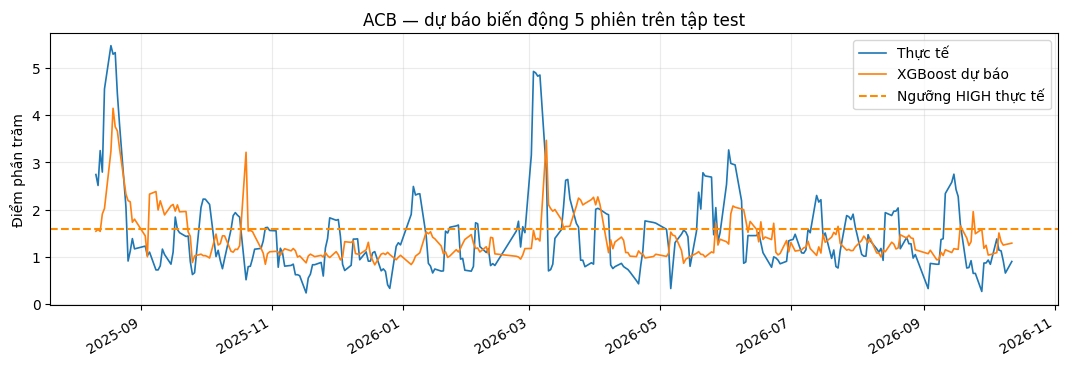

In [6]:
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(comparison["date"], comparison["actual_volatility"], label="Thực tế", linewidth=1.2)
ax.plot(comparison["date"], comparison["predicted_volatility"], label="XGBoost dự báo", linewidth=1.2)
ax.axhline(warning.high_threshold, color="darkorange", linestyle="--", label="Ngưỡng HIGH thực tế")
ax.set(title=f"{ticker} — dự báo biến động 5 phiên trên tập test", ylabel="Điểm phần trăm")
ax.legend(); ax.grid(alpha=.25); fig.autofmt_xdate(); plt.show()

## 5. Đặc trưng và sai số

Các giá trị feature_importances_ dưới đây cho biết mức độ mô hình XGBoost sử dụng từng đặc trưng. Chúng chỉ mang tính mô tả, không chứng minh quan hệ nhân quả. Các đặc trưng lợi suất và trung bình trượt có thể tương quan với nhau.

,Mức độ quan trọng
Đặc trưng,
return_1d,0.025890
volume_change,0.031552
open_close_range,0.034863
volume_to_ma_20,0.047128
return_10d,0.048473
close_to_ma_5,0.049015
close_to_ma_50,0.062871
return_20d,0.063984
high_low_range,0.071793


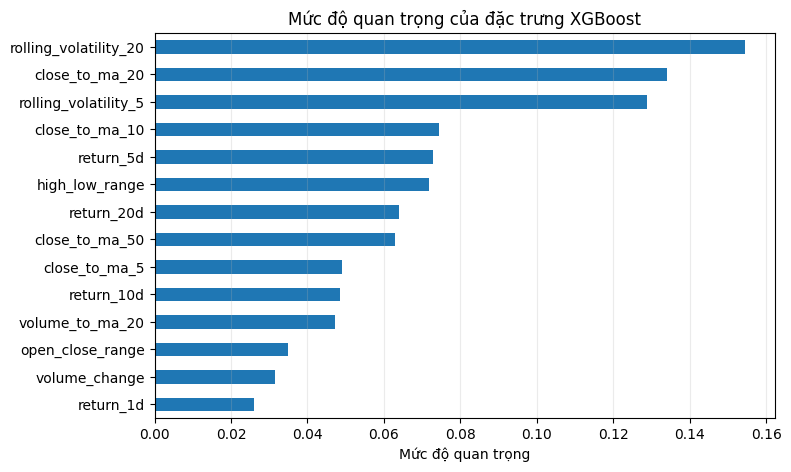

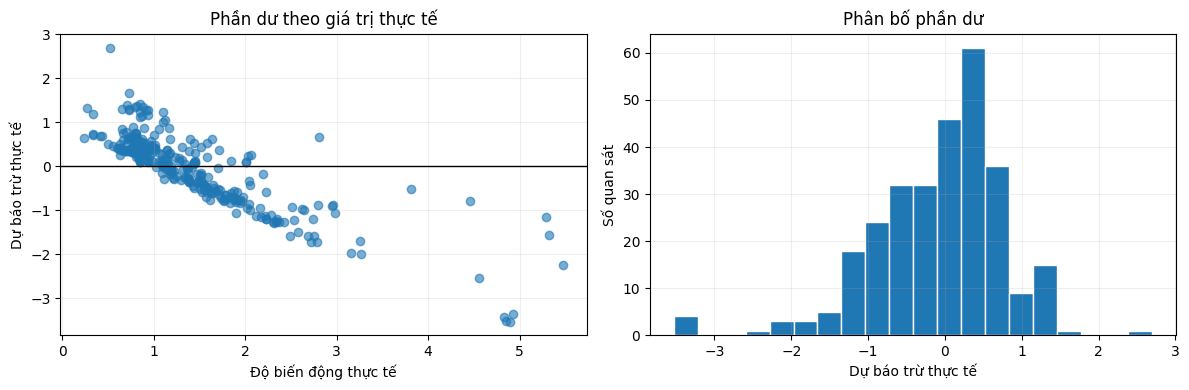

In [7]:
importance = pd.Series(
    model.estimator.feature_importances_, index=dataset.features, name="Mức độ quan trọng"
).sort_values()
display(importance.rename_axis("Đặc trưng").to_frame())
ax = importance.plot.barh(figsize=(8, 5), title="Mức độ quan trọng của đặc trưng XGBoost")
ax.set_xlabel("Mức độ quan trọng"); ax.grid(axis="x", alpha=.25); plt.show()

comparison["residual"] = comparison["predicted_volatility"] - comparison["actual_volatility"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].scatter(comparison["actual_volatility"], comparison["residual"], alpha=.6)
axes[0].axhline(0, color="black", linewidth=1)
axes[0].set(xlabel="Độ biến động thực tế", ylabel="Dự báo trừ thực tế", title="Phần dư theo giá trị thực tế")
axes[1].hist(comparison["residual"], bins=20, edgecolor="white")
axes[1].set(xlabel="Dự báo trừ thực tế", ylabel="Số quan sát", title="Phân bố phần dư")
for ax in axes: ax.grid(alpha=.2)
fig.tight_layout(); plt.show()

## Tổng kết và giới hạn

- Lưới tham số được chọn theo AP của lớp HIGH, với điều kiện RMSE không vượt quá giới hạn đã đặt. Baseline validation dùng để tham khảo độ khó dự báo.
- Mô hình cuối được fit trên toàn bộ dữ liệu trước test. Ngưỡng cảnh báo XGBoost được hiệu chỉnh từ dự báo out-of-fold trên validation, với tỷ lệ cảnh báo tối đa 30% và precision tối thiểu 25%.
- Kết quả test phản ánh hiệu năng lịch sử trên giai đoạn đã dùng trong quá trình phát triển. Cần đánh giá trên dữ liệu tương lai để xác nhận khả năng tổng quát hóa. Cảnh báo HIGH biểu thị độ biến động tương đối cao theo ngưỡng từ train, không phải khuyến nghị mua hoặc bán.

Để tạo artifact theo pipeline, chạy python -m scripts.train --ticker TICKER --model xgboost, sau đó chạy python -m scripts.evaluate --ticker TICKER. Notebook và pipeline cùng gọi tune_xgboost, XGBoostModel và hàm hiệu chỉnh cảnh báo của dự án.

In [20]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, confusion_matrix
from src.models.xgboost_tuning import tune_xgboost
from src.models.xgboost_model import XGBoostModel
from src.evaluation.warning_metrics import calibrate_high_threshold

def evaluate_feature_subset(features):
    features = tuple(features)
    if not features:
        raise ValueError("Danh sách features không được để trống.")

    unknown = set(features) - set(dataset.features)
    if unknown:
        raise ValueError(f"Features không có trong dataset: {sorted(unknown)}")

    # Chọn siêu tham số riêng cho bộ features này bằng các fold thời gian.
    tuning = tune_xgboost(
        dataset.train,
        dataset.validation_folds,
        features,
        dataset.target,
        xgb_settings,
        tuning_config,
        seed=config["seed"],
        high_quantile=warning.q_high,
    )
    params = {**xgb_settings, **tuning["params"]}

    # Tạo dự báo out-of-fold trên validation để hiệu chỉnh ngưỡng HIGH.
    validation_forecasts = []
    for fold_train, fold_validation in dataset.validation_folds:
        fold_model = XGBoostModel(
            features, dataset.target, dataset.horizon,
            params=params, seed=config["seed"],
        ).fit(fold_train)
        validation_forecasts.append(
            fold_model.predict(history, fold_validation["date"])
        )

    validation_pred = (
        pd.concat(validation_forecasts, ignore_index=True)
        .sort_values("date")
        .reset_index(drop=True)
    )
    validation_actual = (
        dataset.validation.sort_values("date")
        .reset_index(drop=True)[["date", dataset.target]]
    )
    validation = validation_actual.merge(
        validation_pred[["date", "predicted_volatility"]],
        on="date",
        validate="one_to_one",
    )

    policy = config.get("alert_policy", {})
    xgb_policy = policy.get("model_overrides", {}).get("xgboost", {})
    max_alert_rate = float(
        xgb_policy.get("max_alert_rate", policy.get("max_alert_rate", 0.15))
    )
    min_precision = float(
        xgb_policy.get("min_precision", policy.get("min_precision", 0.25))
    )

    calibration = calibrate_high_threshold(
        validation[dataset.target],
        validation["predicted_volatility"],
        warning.high_threshold,
        max_alert_rate=max_alert_rate,
        min_precision=min_precision,
    )

    # Fit trên toàn bộ train và đánh giá trên test.
    final_model = XGBoostModel(
        features, dataset.target, dataset.horizon,
        params=params, seed=config["seed"],
    ).fit(dataset.train)
    test_pred = final_model.predict(history, dataset.test["date"])

    test_actual = (
        dataset.test[["date", dataset.target]]
        .rename(columns={dataset.target: "actual_volatility"})
    )
    result = test_actual.merge(
        test_pred[["date", "predicted_volatility"]],
        on="date",
        validate="one_to_one",
    )

    y_true = result["actual_volatility"].to_numpy()
    y_pred = result["predicted_volatility"].to_numpy()

    # Nhãn HIGH thực tế dùng ngưỡng từ train;
    # cảnh báo HIGH dùng ngưỡng đã hiệu chỉnh trên validation.
    actual_high = y_true >= warning.high_threshold
    predicted_high = y_pred >= calibration["threshold"]

    high_matrix = confusion_matrix(
        actual_high,
        predicted_high,
        labels=[False, True],
    )
    high_matrix = pd.DataFrame(
        high_matrix,
        index=["Thực tế không HIGH", "Thực tế HIGH"],
        columns=["Dự báo không HIGH", "Dự báo HIGH"],
    )

    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": mean_squared_error(y_true, y_pred) ** 0.5,
        "r2": r2_score(y_true, y_pred),
        "high_confusion_matrix": high_matrix,
    }

In [27]:
non_select_features = ['volume_change','volume_to_ma_20','open_close_range']
results = []
result = evaluate_feature_subset(dataset.features)
print(result)
for n in non_select_features: 
    candidate_features = [ f for f in dataset.features if f != n]
    result = evaluate_feature_subset(candidate_features)
    print(result)

##print({k: v for k, v in result.items() if k != "high_confusion_matrix"})
##display(result["high_confusion_matrix"])

{'mae': 0.6341851973274343, 'rmse': 0.8501299099077085, 'r2': 0.07442001659620068, 'high_confusion_matrix':                     Dự báo không HIGH  Dự báo HIGH
Thực tế không HIGH                 98          104
Thực tế HIGH                       52           37}
{'mae': 0.6299691800484618, 'rmse': 0.8640699424483117, 'r2': 0.043816692424402004, 'high_confusion_matrix':                     Dự báo không HIGH  Dự báo HIGH
Thực tế không HIGH                102          100
Thực tế HIGH                       56           33}
{'mae': 0.6430104740637298, 'rmse': 0.8585632233036721, 'r2': 0.05596537243623534, 'high_confusion_matrix':                     Dự báo không HIGH  Dự báo HIGH
Thực tế không HIGH                 97          105
Thực tế HIGH                       51           38}
{'mae': 0.6282774879679984, 'rmse': 0.8639650389113124, 'r2': 0.044048851690927426, 'high_confusion_matrix':                     Dự báo không HIGH  Dự báo HIGH
Thực tế không HIGH                104           98
Th